In [ ]:
from cluster_weather_years.constants import PROBS
import os

import pandas as pd
import numpy as np

import itertools
import matplotlib.pyplot as plt
from cluster_weather_years.functions import (
    build_df_centroids,
)
from cluster_weather_years.constants import BASE_OUTPUT, MODELS
from sa_settings import MATCH_COUNTRIES


# 1. Build datasets

In [2]:
# build df
DF_PROD_DEMAND_FNAME = os.path.join(
    BASE_OUTPUT, "dataframes/df_prod_demand_daily_multi_country_WRONG_CAPACITIES.csv"
)
SA_OUTPUT_DIR = os.path.join(BASE_OUTPUT, "simulated_annealing")

df_daily = pd.read_csv(DF_PROD_DEMAND_FNAME, index_col=0)
df_daily["Date"] = pd.to_datetime(df_daily["Date"])
df_daily = df_daily.query("Hydrological_year > 2014 and Hydrological_year < 2044")

vars_to_match = []
for country in MATCH_COUNTRIES:
    vars_to_match.extend(
        [
            f"{country}_OFF_prod",
            f"{country}_ON_prod",
            f"{country}_SOLAR_prod",
            f"{country}_Demand",
        ]
    )

In [5]:
mlz_models = ["cmcc_cm2_sr5", "ec_earth3", "mpi_esm_1_2_hr"]
all_models = MODELS
mlz_years = range(2025, 2037)
# combine these models and years into tuples
mlz_modelyears = list(itertools.product(mlz_models, mlz_years))
slice_modelyears = list(itertools.product(all_models, mlz_years))
mlz_model_allyears = list(itertools.product(mlz_models, range(2015, 2044)))

In [6]:
# also in capacity factor?
df_cf = pd.read_csv(
    "/net/pc230050/nobackup/users/duinen/04_weather_year_selection/outputs/dataframes/df_daily.csv",
    index_col=0,
)

datasets = {}
datasets["MLZ_25"] = build_df_centroids(df_daily, mlz_modelyears, mode="Calendar_year")
datasets["Slice_72"] = build_df_centroids(
    df_daily, slice_modelyears, mode="Calendar_year"
)
datasets["mlz_models_all_years"] = build_df_centroids(
    df_daily, mlz_model_allyears, mode="Calendar_year"
)

datasets_cf = {}
datasets_cf["MLZ_25"] = build_df_centroids(df_cf, mlz_modelyears, mode="Calendar_year")
datasets_cf["Slice_72"] = build_df_centroids(
    df_cf, slice_modelyears, mode="Calendar_year"
)
datasets_cf["mlz_models_all_years"] = build_df_centroids(
    df_cf, mlz_model_allyears, mode="Calendar_year"
)

In [7]:
mlz_q = datasets["MLZ_25"]["NL_SOLAR_prod"].quantile(PROBS)
slice_q = datasets["Slice_72"]["NL_SOLAR_prod"].quantile(PROBS)
mlzmodels_q = datasets["mlz_models_all_years"]["NL_SOLAR_prod"].quantile(PROBS)
df_q = df_daily["NL_SOLAR_prod"].quantile(PROBS)

mlz_q_cf = datasets_cf["MLZ_25"]["NL_SOLAR"].quantile(PROBS)
slice_q_cf = datasets_cf["Slice_72"]["NL_SOLAR"].quantile(PROBS)
mlzmodels_q_cf = datasets_cf["mlz_models_all_years"]["NL_SOLAR"].quantile(PROBS)
df_q_cf = df_cf["NL_SOLAR"].quantile(PROBS)

# 2. Analysis

In [ ]:
(
    datasets["MLZ_25"]["NL_SOLAR_prod"].mean() - df_daily["NL_SOLAR_prod"].mean()
) / df_daily["NL_SOLAR_prod"].mean() * 100

-2.3236274533289283

In [9]:
datasets["MLZ_25"]["NL_SOLAR_prod"].median() - df_daily["NL_SOLAR_prod"].median()

-3.741899999999987

In [ ]:
summer = [4, 5, 6, 7, 8, 9]
# summer = [12, 1, 2]
(
    datasets["MLZ_25"].query("Date.dt.month in @summer")["NL_SOLAR_prod"].mean()
    - df_daily.query("Date.dt.month in @summer")["NL_SOLAR_prod"].mean()
) / df_daily.query("Date.dt.month in @summer")["NL_SOLAR_prod"].mean() * 100

-1.8300389378428397

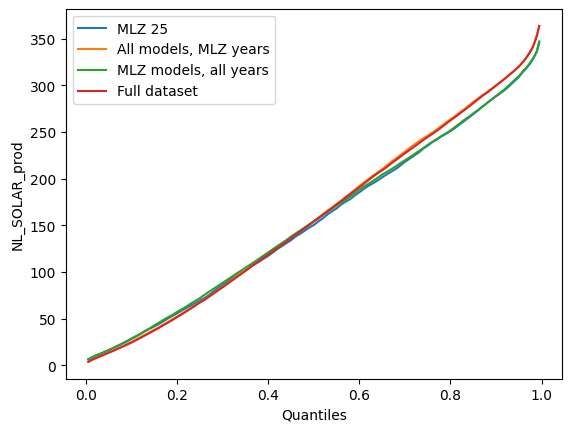

In [11]:
plt.plot(PROBS, mlz_q, label="MLZ 25")
plt.plot(PROBS, slice_q, label="All models, MLZ years")
plt.plot(PROBS, mlzmodels_q, label="MLZ models, all years")
plt.plot(PROBS, df_q, label="Full dataset")
plt.xlabel("Quantiles")
plt.ylabel("NL_SOLAR_prod")
plt.legend()

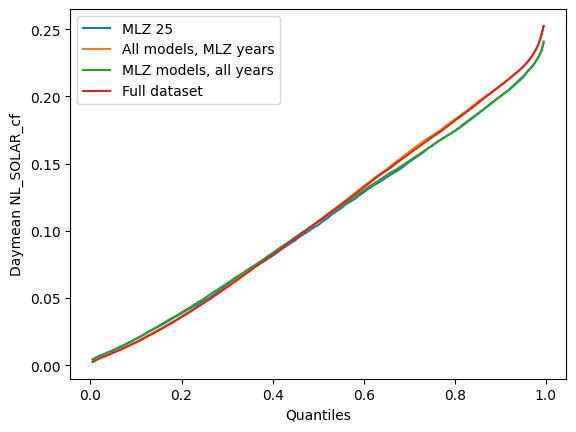

In [12]:
plt.plot(PROBS, mlz_q_cf, label="MLZ 25")
plt.plot(PROBS, slice_q_cf, label="All models, MLZ years")
plt.plot(PROBS, mlzmodels_q_cf, label="MLZ models, all years")
plt.plot(PROBS, df_q_cf, label="Full dataset")
plt.xlabel("Quantiles")
plt.ylabel("Daymean NL_SOLAR_cf")
plt.legend()

## Check with hourly

In [13]:
from cluster_weather_years.constants import (
    COUNTRIES,
    MODELS,
    MODELS_FNAME,
    OUTPUT_DIR_SOLAR,
    OUTPUT_DIR_TEMP,
    OUTPUT_DIR_WIND,
    YEARS,
)

In [14]:
frames_hourly = []

for model_fname, model_name in zip(MODELS_FNAME, MODELS):
    for year in YEARS:
        file_wind_off = f"P_CMI6_{model_fname}_WOF_NA---_Pecd_NUT0_S{year}01010000_E{year}12312300_CFR_TIM_01h_NA-_noc_org_20_SP245_ReGrB_PhM04_PECD4.2_fv1.csv"
        file_wind_on = f"P_CMI6_{model_fname}_WON_NA---_Pecd_NUT0_S{year}01010000_E{year}12312300_CFR_TIM_01h_NA-_noc_org_30_SP245_ReGrB_PhM04_PECD4.2_fv1.csv"
        file_solar = f"P_CMI6_{model_fname}_SPV_0000m_Pecd_NUT0_S{year}01010000_E{year}12312300_CFR_TIM_01h_NA-_noc_org_61_SP245_NA---_PhM03_PECD4.2_fv1.csv"
        file_temp = f"P_CMI6_{model_fname}_TA-_0002m_Pecd_NUT0_S{year}01010000_E{year}12312300_INS_TIM_01h_NA-_cdf_org_NA_SP245_NA---_NA---_PECD4.2_fv1.csv"

        df_wind_off = pd.read_csv(
            os.path.join(OUTPUT_DIR_WIND, file_wind_off),
            skiprows=52,
        )
        df_wind_on = pd.read_csv(
            os.path.join(OUTPUT_DIR_WIND, file_wind_on),
            skiprows=52,
        )

        df_solar = pd.read_csv(
            os.path.join(OUTPUT_DIR_SOLAR, file_solar),
            skiprows=52,
        )

        df_temp = pd.read_csv(
            os.path.join(OUTPUT_DIR_TEMP, file_temp),
            skiprows=52,
        )

        df_year = pd.DataFrame(
            {
                "Date": df_wind_off["Date"],
                **{
                    f"{country}_OFF": df_wind_off[f"{country}_OFF"]
                    for country in COUNTRIES
                },
                **{f"{country}_ON": df_wind_on[f"{country}"] for country in COUNTRIES},
                **{f"{country}_SOLAR": df_solar[f"{country}"] for country in COUNTRIES},
                **{f"{country}_TEMP": df_temp[f"{country}"] for country in COUNTRIES},
                "model": model_name,
            }
        )

        frames_hourly.append(df_year)

df_hourly = pd.concat(frames_hourly, ignore_index=True)
df_hourly["Date"] = pd.to_datetime(df_hourly["Date"])

In [15]:
df_hourly["NL_SOLAR"].replace(0, np.nan, inplace=True)

/tmp/ipykernel_1820098/386199233.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_hourly["NL_SOLAR"].replace(0, np.nan, inplace=True)


In [16]:
df_hourly_mlz = df_hourly.query("model in @mlz_models")

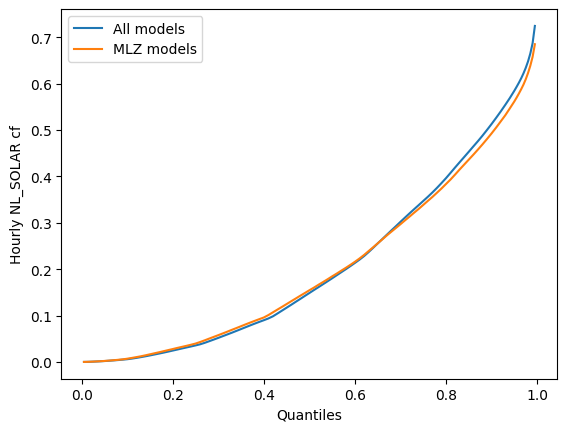

In [17]:
plt.plot(PROBS, df_hourly["NL_SOLAR"].quantile(PROBS), label="All models")
plt.plot(PROBS, df_hourly_mlz["NL_SOLAR"].quantile(PROBS), label="MLZ models")
plt.xlabel("Quantiles")
plt.ylabel("Hourly NL_SOLAR cf")
plt.legend()